In [ ]:
# 🚗 Car Price Prediction with Machine Learning

### CodeAlpha Data Science Internship

## Project Objective

The objective of this project is to predict the selling price of used cars using Machine Learning.

The project uses different car features such as manufacturing year, present price, kilometres driven, fuel type, transmission, and ownership.

A regression model will be trained to understand the relationship between these features and car selling prices.

## Technologies Used

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn
- Jupyter Notebook

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_csv("car data.csv")

df.head()

,Car_Name,Year,Selling_Price,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


In [3]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 301
Number of columns: 9


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    object 
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Driven_kms     301 non-null    int64  
 5   Fuel_Type      301 non-null    object 
 6   Selling_type   301 non-null    object 
 7   Transmission   301 non-null    object 
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 21.3+ KB


In [5]:
print("Missing values:")
print(df.isnull().sum())

Missing values:
Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Driven_kms       0
Fuel_Type        0
Selling_type     0
Transmission     0
Owner            0
dtype: int64


In [6]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 2


In [7]:
df = df.drop_duplicates()

print("Dataset shape after removing duplicates:", df.shape)

Dataset shape after removing duplicates: (299, 9)


In [8]:
df.describe()

,Year,Selling_Price,Present_Price,Driven_kms,Owner
count,299.000000,299.000000,299.000000,299.000000,299.000000
mean,2013.615385,4.589632,7.541037,36916.752508,0.043478
std,2.896868,4.984240,8.566332,39015.170352,0.248720
min,2003.000000,0.100000,0.320000,500.000000,0.000000
25%,2012.000000,0.850000,1.200000,15000.000000,0.000000
50%,2014.000000,3.510000,6.100000,32000.000000,0.000000
75%,2016.000000,6.000000,9.840000,48883.500000,0.000000
max,2018.000000,35.000000,92.600000,500000.000000,3.000000


In [9]:
print("Fuel Types:")
print(df["Fuel_Type"].unique())

print("\nSelling Types:")
print(df["Selling_type"].unique())

print("\nTransmission Types:")
print(df["Transmission"].unique())

print("\nPrevious Owners:")
print(df["Owner"].unique())

Fuel Types:
['Petrol' 'Diesel' 'CNG']

Selling Types:
['Dealer' 'Individual']

Transmission Types:
['Manual' 'Automatic']

Previous Owners:
[0 1 3]


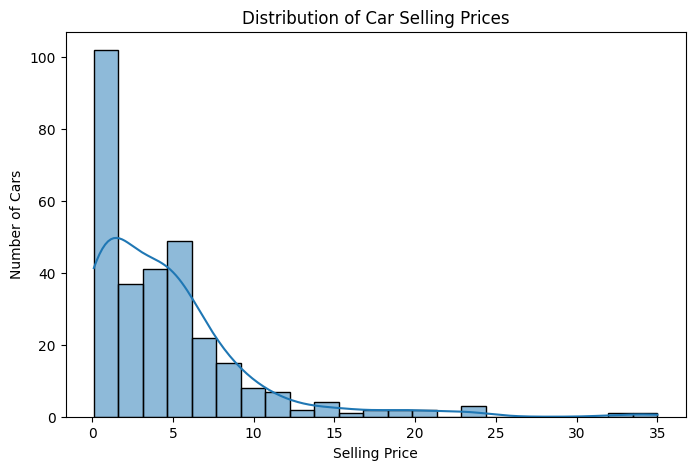

In [10]:
plt.figure(figsize=(8, 5))

sns.histplot(df["Selling_Price"], kde=True)

plt.title("Distribution of Car Selling Prices")
plt.xlabel("Selling Price")
plt.ylabel("Number of Cars")

plt.show()

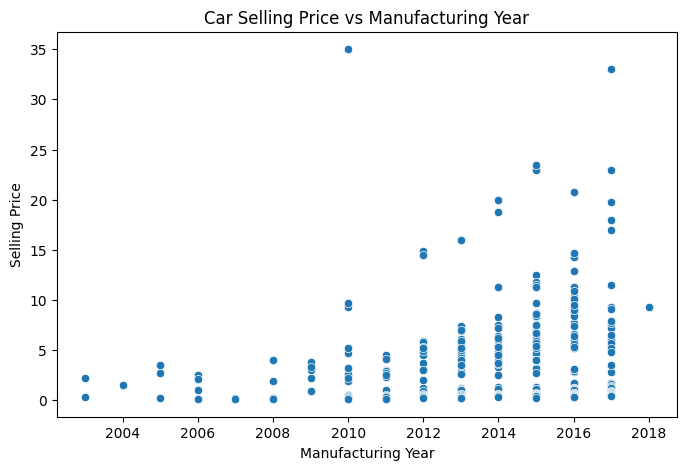

In [11]:
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x="Year", y="Selling_Price")

plt.title("Car Selling Price vs Manufacturing Year")
plt.xlabel("Manufacturing Year")
plt.ylabel("Selling Price")

plt.show()

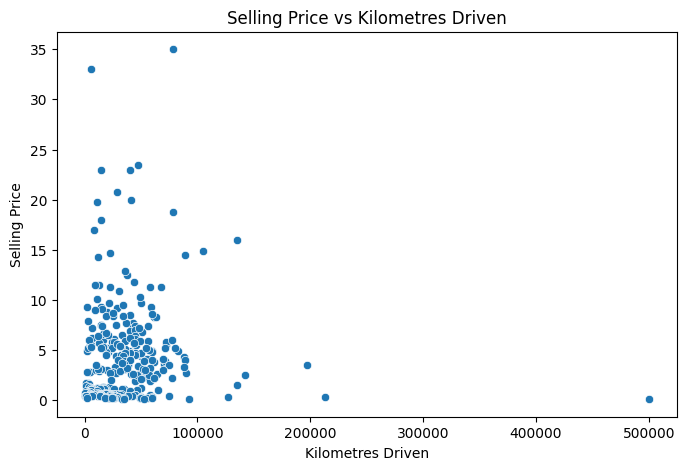

In [12]:
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x="Driven_kms", y="Selling_Price")

plt.title("Selling Price vs Kilometres Driven")
plt.xlabel("Kilometres Driven")
plt.ylabel("Selling Price")

plt.show()

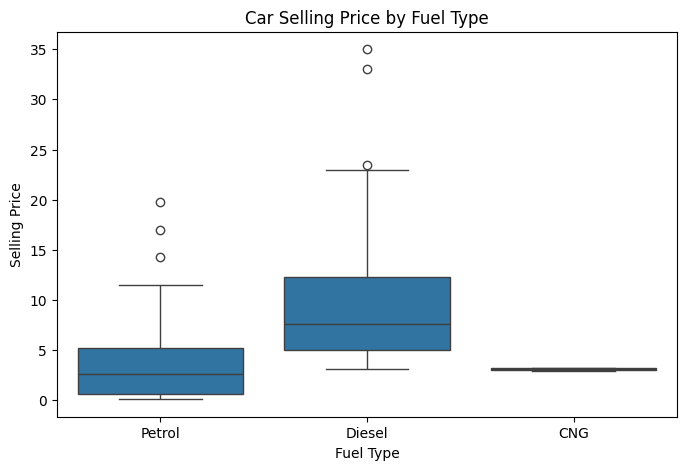

In [13]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Fuel_Type", y="Selling_Price")

plt.title("Car Selling Price by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Selling Price")

plt.show()

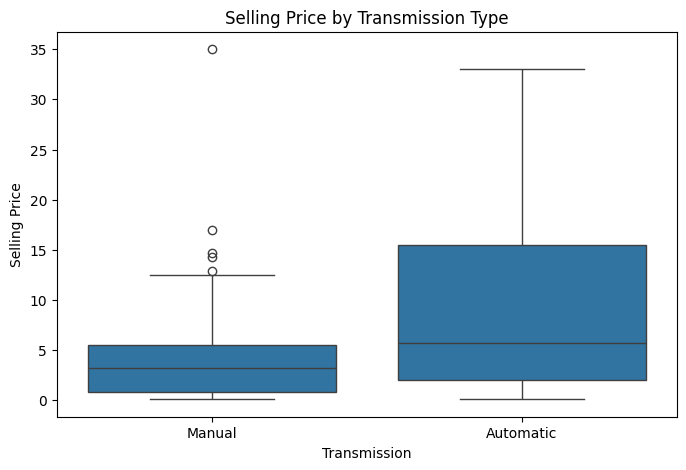

In [14]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Transmission", y="Selling_Price")

plt.title("Selling Price by Transmission Type")
plt.xlabel("Transmission")
plt.ylabel("Selling Price")

plt.show()

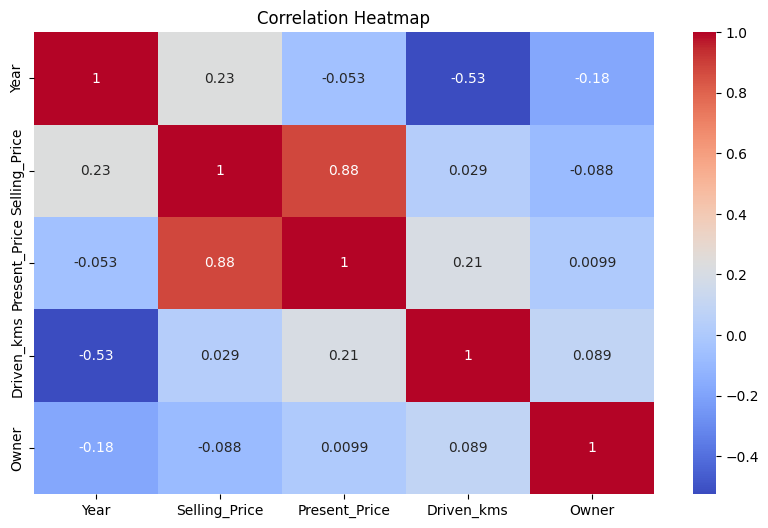

In [15]:
plt.figure(figsize=(10, 6))

numeric_df = df.select_dtypes(include=np.number)

sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm")

plt.title("Correlation Heatmap")

plt.show()

In [16]:
X = df.drop("Selling_Price", axis=1)
y = df["Selling_Price"]

print("Input Features:")
print(X.head())

print("\nTarget Values:")
print(y.head())

Input Features:
  Car_Name  Year  Present_Price  Driven_kms Fuel_Type Selling_type  \
0     ritz  2014           5.59       27000    Petrol       Dealer   
1      sx4  2013           9.54       43000    Diesel       Dealer   
2     ciaz  2017           9.85        6900    Petrol       Dealer   
3  wagon r  2011           4.15        5200    Petrol       Dealer   
4    swift  2014           6.87       42450    Diesel       Dealer   

  Transmission  Owner  
0       Manual      0  
1       Manual      0  
2       Manual      0  
3       Manual      0  
4       Manual      0  

Target Values:
0    3.35
1    4.75
2    7.25
3    2.85
4    4.60
Name: Selling_Price, dtype: float64


In [17]:
X = pd.get_dummies(X, drop_first=True)

print("Converted Dataset:")
X.head()

Converted Dataset:


,Year,Present_Price,Driven_kms,Owner,Car_Name_Activa 3g,Car_Name_Activa 4g,Car_Name_Bajaj ct 100,Car_Name_Bajaj Avenger 150,Car_Name_Bajaj Avenger 150 street,Car_Name_Bajaj Avenger 220,...,Car_Name_swift,Car_Name_sx4,Car_Name_verna,Car_Name_vitara brezza,Car_Name_wagon r,Car_Name_xcent,Fuel_Type_Diesel,Fuel_Type_Petrol,Selling_type_Individual,Transmission_Manual
0,2014,5.59,27000,0,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,True
1,2013,9.54,43000,0,False,False,False,False,False,False,...,False,True,False,False,False,False,True,False,False,True
2,2017,9.85,6900,0,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,True
3,2011,4.15,5200,0,False,False,False,False,False,False,...,False,False,False,False,True,False,False,True,False,True
4,2014,6.87,42450,0,False,False,False,False,False,False,...,True,False,False,False,False,False,True,False,False,True


In [18]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Training records: 239
Testing records: 60


In [19]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [20]:
y_pred = model.predict(X_test)

print("Actual Prices:")
print(y_test.head().values)

print("\nPredicted Prices:")
print(y_pred[:5])

Actual Prices:
[8.99 8.35 0.45 7.45 5.25]

Predicted Prices:
[ 8.88188372  8.17760014  1.01356874  6.64719403 10.23372694]


In [21]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error:", round(mae, 2))
print("Mean Squared Error:", round(mse, 2))
print("Root Mean Squared Error:", round(rmse, 2))
print("R2 Score:", round(r2, 4))

Mean Absolute Error: 2.62
Mean Squared Error: 17.04
Root Mean Squared Error: 4.13
R2 Score: 0.3388


In [22]:
comparison = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred
})

comparison.head(10)

,Actual Price,Predicted Price
0,8.99,8.881884
1,8.35,8.177600
2,0.45,1.013569
3,7.45,6.647194
4,5.25,10.233727
5,5.25,4.832550
6,5.85,8.140994
7,1.15,2.608042
8,9.25,15.559033
9,0.38,4.492654


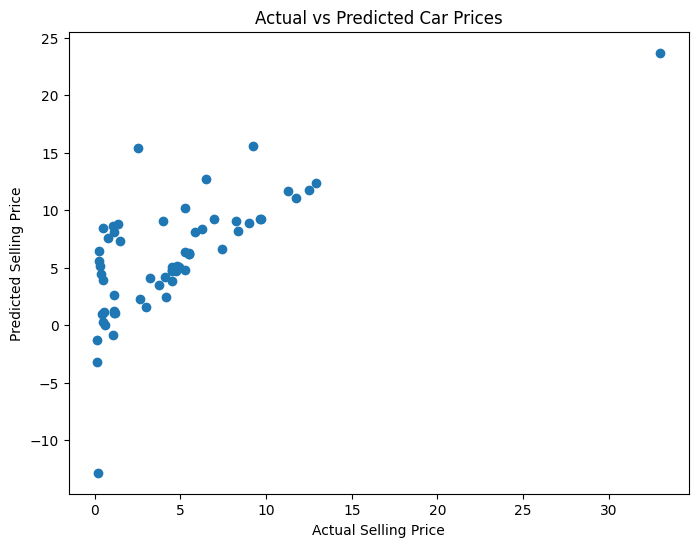

In [23]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Selling Price")
plt.ylabel("Predicted Selling Price")
plt.title("Actual vs Predicted Car Prices")

plt.show()

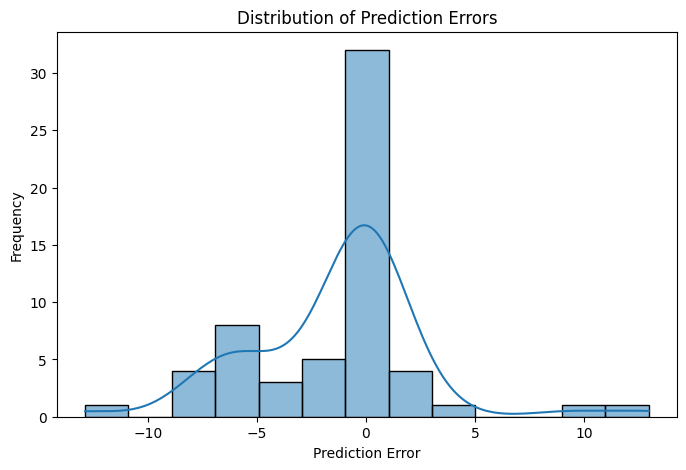

In [24]:
errors = y_test - y_pred

plt.figure(figsize=(8, 5))

sns.histplot(errors, kde=True)

plt.title("Distribution of Prediction Errors")
plt.xlabel("Prediction Error")
plt.ylabel("Frequency")

plt.show()

In [25]:
from sklearn.tree import DecisionTreeRegressor

dt_model = DecisionTreeRegressor(random_state=42)

dt_model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [26]:
dt_pred = dt_model.predict(X_test)

print("Actual Prices:")
print(y_test.head().values)

print("\nDecision Tree Predicted Prices:")
print(dt_pred[:5])

Actual Prices:
[8.99 8.35 0.45 7.45 5.25]

Decision Tree Predicted Prices:
[ 7.25  9.1   0.45  7.2  14.5 ]


In [27]:
dt_mae = mean_absolute_error(y_test, dt_pred)
dt_mse = mean_squared_error(y_test, dt_pred)
dt_rmse = np.sqrt(dt_mse)
dt_r2 = r2_score(y_test, dt_pred)

print("Decision Tree MAE:", round(dt_mae, 2))
print("Decision Tree MSE:", round(dt_mse, 2))
print("Decision Tree RMSE:", round(dt_rmse, 2))
print("Decision Tree R2 Score:", round(dt_r2, 4))

Decision Tree MAE: 1.39
Decision Tree MSE: 10.22
Decision Tree RMSE: 3.2
Decision Tree R2 Score: 0.6035


In [28]:
model_comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Decision Tree"],
    "MAE": [mae, dt_mae],
    "RMSE": [rmse, dt_rmse],
    "R2 Score": [r2, dt_r2]
})

model_comparison

,Model,MAE,RMSE,R2 Score
0,Linear Regression,2.622629,4.128261,0.338751
1,Decision Tree,1.393500,3.196887,0.603462


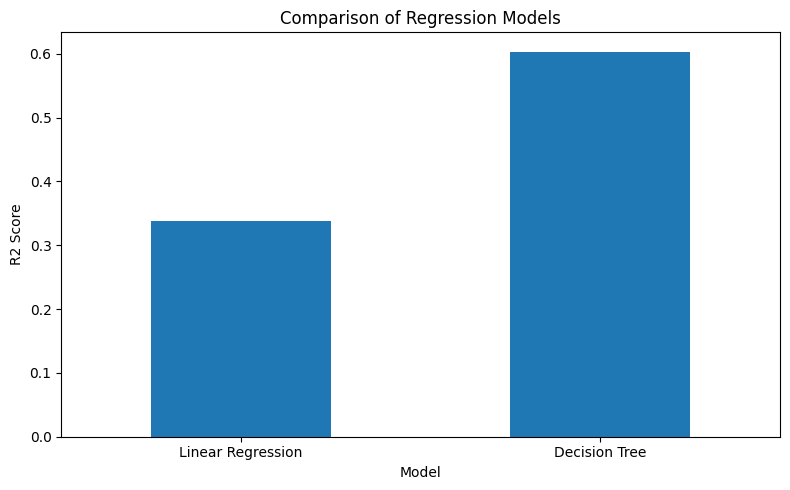

In [29]:
model_comparison.plot(
    x="Model",
    y="R2 Score",
    kind="bar",
    figsize=(8, 5),
    legend=False
)

plt.title("Comparison of Regression Models")
plt.ylabel("R2 Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [30]:
model_comparison = model_comparison.sort_values(
    by=["R2 Score", "RMSE"],
    ascending=[False, True]
)

model_comparison

,Model,MAE,RMSE,R2 Score
1,Decision Tree,1.393500,3.196887,0.603462
0,Linear Regression,2.622629,4.128261,0.338751


In [31]:
if r2 >= dt_r2:
    best_model = model
    best_model_name = "Linear Regression"
else:
    best_model = dt_model
    best_model_name = "Decision Tree"

print("Best Model:", best_model_name)

Best Model: Decision Tree


In [32]:
new_car = pd.DataFrame({
    "Car_Name": ["ritz"],
    "Year": [2017],
    "Present_Price": [5.5],
    "Driven_kms": [25000],
    "Fuel_Type": ["Petrol"],
    "Selling_type": ["Dealer"],
    "Transmission": ["Manual"],
    "Owner": [0]
})

new_car_encoded = pd.get_dummies(new_car, drop_first=True)

new_car_encoded = new_car_encoded.reindex(
    columns=X.columns,
    fill_value=0
)

predicted_price = best_model.predict(new_car_encoded)

print("Predicted Car Selling Price:", round(predicted_price[0], 2))

Predicted Car Selling Price: 5.25


## Final Result

The project successfully developed a Car Price Prediction system using Machine Learning.

Two regression algorithms were implemented:

1. Linear Regression
2. Decision Tree Regression

Both models were evaluated using MAE, MSE, RMSE and R2 Score.

The better-performing model was selected to predict the selling price of a new car based on its features.

The project demonstrates how Machine Learning can be used for used-car price estimation.

## Conclusion

This project demonstrated the use of Machine Learning for predicting used-car prices.

The dataset was cleaned and analyzed using Pandas, NumPy, Matplotlib and Seaborn.

Different car features were used to train regression models. Linear Regression and Decision Tree Regression were compared using evaluation metrics.

The best-performing model was used to predict the selling price of a new car.

This project helped in understanding data preprocessing, feature engineering, regression algorithms and model evaluation.